<a href="https://colab.research.google.com/github/harshithakathir28-wq/DL_EXP7/blob/main/EX7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PART A

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
After Reshaping:
Training Data: (60000, 784)
Testing Data: (10000, 784)


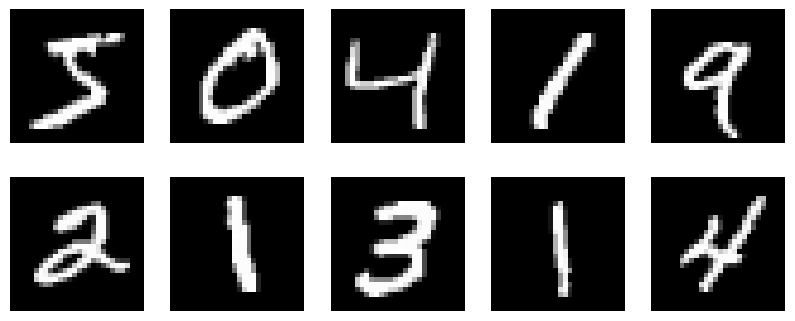

In [1]:
# Experiment 7
# Roll No: 24BAD034

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("After Reshaping:")
print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.show()

PART B

In [2]:
# Experiment 7
# Roll No: 24BAD034

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

input_layer = Input(shape=(784,))


encoder = Dense(128, activation='relu')(input_layer)
encoder = Dense(64, activation='relu')(encoder)


bottleneck = Dense(32, activation='relu')(encoder)


decoder = Dense(64, activation='relu')(bottleneck)
decoder = Dense(128, activation='relu')(decoder)

output_layer = Dense(784, activation='sigmoid')(decoder)

autoencoder = Model(input_layer, output_layer)

encoder_model = Model(input_layer, bottleneck)

autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

PART C

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.0643 - val_loss: 0.0385
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0326 - val_loss: 0.0276
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0248 - val_loss: 0.0220
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0212 - val_loss: 0.0197
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0192 - val_loss: 0.0180
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0177 - val_loss: 0.0165
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0164 - val_loss: 0.0155
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0155 - val_loss: 0.0145
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0146 - val_loss: 0.0138
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0139 - val_loss: 0.0134
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0134
Test Reconstruction MSE: 0.013357640244066715


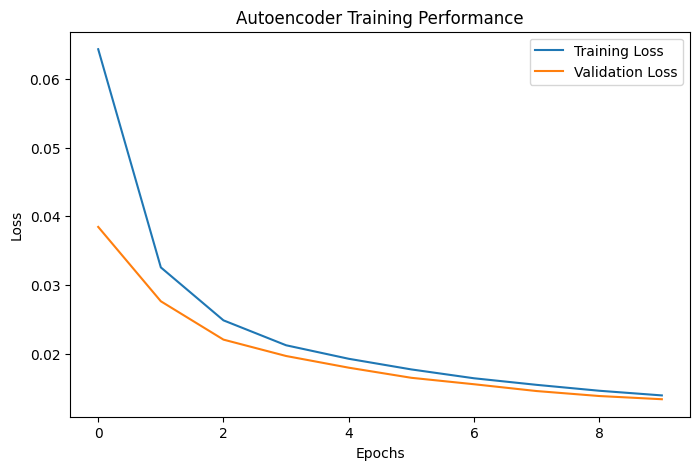

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step


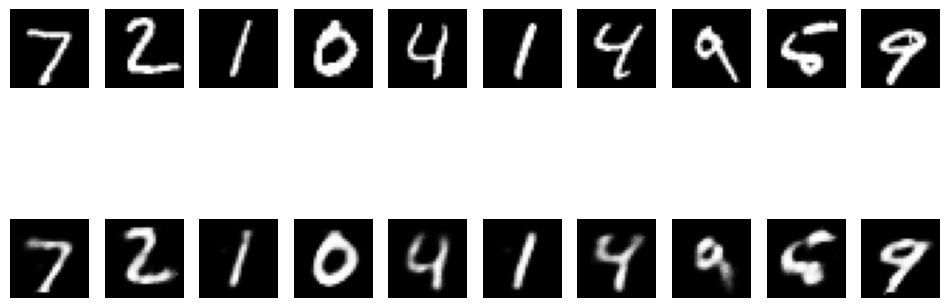

In [3]:
# Experiment 7
# Roll No: 24BAD034

history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)


test_loss = autoencoder.evaluate(x_test, x_test)

print("Test Reconstruction MSE:", test_loss)

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Autoencoder Training Performance')

plt.legend()
plt.show()

reconstructed = autoencoder.predict(x_test[:10])

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.show()

PART D

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Original Data Dimensions: (10000, 784)
Compressed Data Dimensions: (10000, 32)


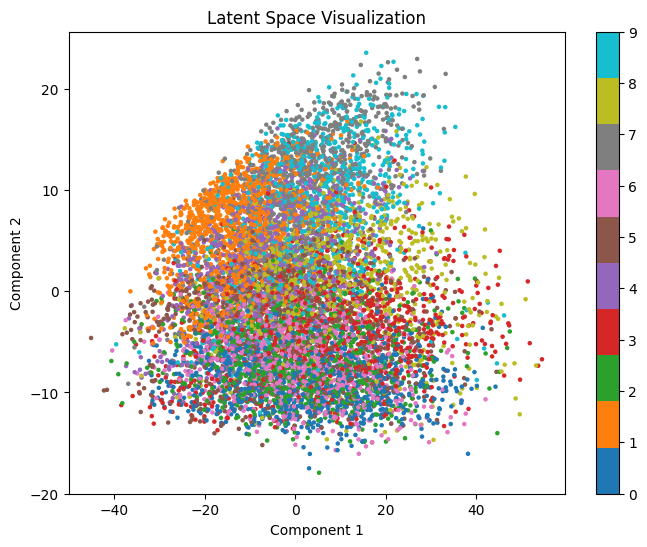

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step


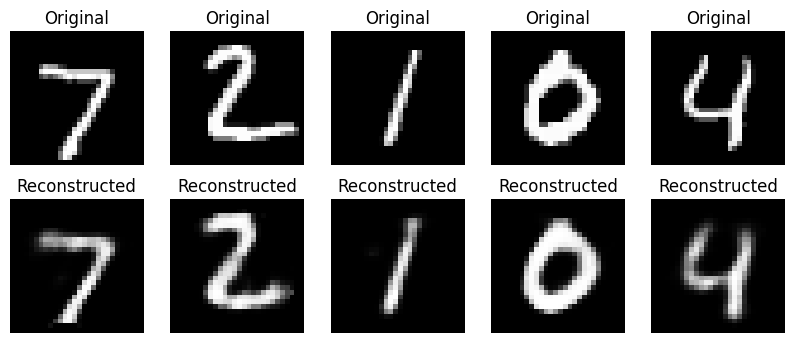

Dimensionality Reduction Completed Successfully!


In [5]:
# Experiment 7
# Roll No: 24BAD034

from sklearn.decomposition import PCA
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input

latent_features = encoder_model.predict(x_test)

print("Original Data Dimensions:", x_test.shape)
print("Compressed Data Dimensions:", latent_features.shape)

pca = PCA(n_components=2)

reduced_features = pca.fit_transform(latent_features)

plt.figure(figsize=(8, 6))

plt.scatter(
    reduced_features[:, 0],
    reduced_features[:, 1],
    c=y_test,
    cmap='tab10',
    s=5
)

plt.colorbar()
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("Latent Space Visualization")

plt.show()


decoder_input = Input(shape=(32,))

x = autoencoder.layers[4](decoder_input)
x = autoencoder.layers[5](x)
decoder_output = autoencoder.layers[6](x)

decoder_model = Model(decoder_input, decoder_output)

compressed = encoder_model.predict(x_test[:5])
reconstructed_images = decoder_model.predict(compressed)

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.show()

print("Dimensionality Reduction Completed Successfully!")